# House Prices: эксперименты

Все эксперименты по шагам: предобработка, классические модели, Optuna, новые признаки, нейросеть, ансамбли. Результаты каждого запуска пишутся в `outputs/results.csv`.

## Подготовка

In [1]:
# Автоперезагрузка модулей из src при их изменении
%load_ext autoreload
%autoreload 2

In [2]:
# Базовые библиотеки
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

# Функции из src
from src.data import load_data, save_submission, build_preprocessor
from src.validation import cross_validate, log_result
from src.models import build_model
from src.features import add_features
from src.tuning import tune

import optuna

import warnings
warnings.filterwarnings("ignore", message="Found unknown categories")
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [3]:
# Загрузка конфига и данных
config = OmegaConf.load("config.yaml")
X, y, X_test, test_ids = load_data(config)

In [4]:
# Хелпер: собрать модель из конфига, прогнать CV и записать результат в журнал
def run_model(cfg, name=None):
    model = build_model(cfg)
    scores, _ = cross_validate(model, X, y, X_test, cfg)
    features = list(cfg.features.numeric) + list(cfg.features.categorical) + list(cfg.features.log_numeric)
    params = OmegaConf.to_container(cfg.model.params, resolve=True)
    log_result(cfg, name or cfg.model.name, params, features, scores)
    return float(round(scores.mean(), 4)), float(round(scores.std(), 4))

## Шаг 3. Бейзлайн

In [7]:
# 3.2 Бейзлайн: всем домам медианная цена
from sklearn.dummy import DummyRegressor

scores, _ = cross_validate(DummyRegressor(strategy="median"), X, y, X_test, config)
log_result(config, "median", {}, [], scores)
round(scores.mean(), 4), round(scores.std(), 4)

(np.float64(0.3998), np.float64(0.0118))

In [8]:
# 3.3 Линейная регрессия на 4 сильнейших признаках: журнал и сабмит
print(run_model(config))
_, test_pred = cross_validate(build_model(config), X, y, X_test, config)
save_submission(test_ids, test_pred, config, "baseline_linreg_4features")

(np.float64(0.1842), np.float64(0.0296))


'outputs\\submission_baseline_linreg_4features.csv'

## Шаг 4. Предобработка

In [7]:
# 4.1 Все 79 признаков как есть, Ridge(alpha=10): точка отсчёта
print(run_model(config))

(np.float64(0.1445), np.float64(0.0425))


In [12]:
# 4.2 Проверка: какие пропуски остались
print(X.isna().sum()[X.isna().sum() > 0])
print(X_test.isna().sum()[X_test.isna().sum() > 0])

LotFrontage    259
Electrical       1
GarageYrBlt     81
dtype: int64
MSZoning         4
LotFrontage    227
Utilities        2
Exterior1st      1
Exterior2nd      1
KitchenQual      1
Functional       2
GarageYrBlt     78
SaleType         1
dtype: int64


In [13]:
# 4.2 NaN «объекта нет» → "None" / 0
print(run_model(config, "ridge_fill_absent"))

(np.float64(0.1447), np.float64(0.0428))


In [25]:
# 4.3 Проверка: порядковые столбцы стали числами
print(X[["KitchenQual", "FireplaceQu", "BsmtExposure", "Functional"]].head())
print(X["KitchenQual"].value_counts())

   KitchenQual  FireplaceQu  BsmtExposure  Functional
0            4            0             1           7
1            3            3             4           7
2            4            3             2           7
3            4            4             1           7
4            4            3             3           7
KitchenQual
3    735
4    586
5    100
2     39
Name: count, dtype: int64


In [26]:
# 4.3 Порядковые категории → числа
print(run_model(config, "ridge_ordinal"))

(np.float64(0.143), np.float64(0.0419))


In [29]:
# 4.4 MSSubClass → категория
print(run_model(config, "ridge_mssubclass_cat"))

(np.float64(0.1421), np.float64(0.0421))


### Выводы 4.1–4.4

| Шаг | Изменение | CV RMSE |
| --- | --- | --- |
| 4.1 | все 79 признаков как есть, Ridge(alpha=10) | 0.1445 ± 0.0425 |
| 4.2 | NaN «объекта нет» → "None" / 0 | 0.1447 ± 0.0428 |
| 4.3 | порядковые категории → числа (без PoolQC) | 0.1430 ± 0.0419 |
| 4.4 | MSSubClass → категория | 0.1421 ± 0.0421 |

- 4.2 по CV ничего не дал: информация «объекта нет» уже была в других столбцах (Fireplaces = 0, GarageCars = 0).
- 4.3: PoolQC убрали. Бассейн есть у 7 домов, после StandardScaler значение уходило на ~17 стандартных отклонений, а выброс 1299 учил модель «бассейн = дешевле». С PoolQC CV был 0.1584.
- 4.4: заполнение LotFrontage медианой по району проверили, эффекта нет (0.1421 → 0.1421). Оставили общую медиану.
- Разброс ± 0.04 почти целиком даёт один фолд с выбросами 524 и 1299, поэтому эффекты небольших изменений пока плохо видны.

In [33]:
# 4.5 Скошенные площади → log_numeric
print(run_model(config, "ridge_log_areas"))

(0.1332, 0.0328)


In [35]:
# 4.6 Без выбросов 524 и 1299
print(X.shape, y.shape)
print(run_model(config, "ridge_drop_outliers"))

(1458, 79) (1458,)
(0.1116, 0.0119)


In [38]:
# 4.7 Без почти константных, дублей и почти нулевых признаков + сабмит
print(run_model(config, "ridge_step4_final"))
_, test_pred = cross_validate(build_model(config), X, y, X_test, config)
save_submission(test_ids, test_pred, config, "ridge_preprocessed")

(0.1112, 0.0114)


'outputs\\submission_ridge_preprocessed.csv'

### Выводы 4.5–4.7 и итог предобработки

| Шаг | Изменение | CV RMSE |
| --- | --- | --- |
| 4.5 | 9 скошенных площадей → log1p | 0.1332 ± 0.0328 |
| 4.6 | убрали выбросы 524 и 1299 из train | 0.1116 ± 0.0119 |
| 4.7 | убрали 13 почти константных, дублирующих и почти нулевых признаков | 0.1112 ± 0.0114 |

- 4.5 дал самый большой прирост: цена в логарифме, и площади в логарифме дают связь «процент к проценту». Заодно сжался хвост огромных площадей.
- 4.6: разброс по фолдам упал втрое. Часть прироста CV «бесплатная»: трудные дома ушли из валидации. В test остался похожий дом (Id 2550), поэтому Kaggle хуже CV.
- 4.7: качество то же, признаков 65 вместо 78. При равном качестве выбираем более простую модель.

**Итог шага 4:** Ridge(alpha=10) CV 0.1445 → 0.1112, Kaggle 0.18030 (бейзлайн на 4 признаках) → 0.12569. CV стал примерно на 0.015 оптимистичнее Kaggle.

## Шаг 5. 1 фолд против 5

In [39]:
# 5 Одна модель на всём train против среднего 5 фолдов
_, cv_pred = cross_validate(build_model(config), X, y, X_test, config)

full_model = build_model(config)
full_model.fit(X, y)
full_pred = full_model.predict(X_test)

diff = np.abs(np.expm1(full_pred) - np.expm1(cv_pred)) / np.expm1(cv_pred)
print(f"Средняя разница: {diff.mean():.2%}, максимальная: {diff.max():.2%}")
save_submission(test_ids, full_pred, config, "ridge_full_train")

Средняя разница: 0.25%, максимальная: 2.56%


'outputs\\submission_ridge_full_train.csv'

### Вывод: 1 модель против среднего 5 фолдов

| Вариант | Kaggle |
| --- | --- |
| среднее 5 моделей фолдов | 0.12569 |
| одна модель на всём train | 0.12598 |

Предсказания отличаются в среднем на 0.25% (максимум 2.56%), на Kaggle разница 0.0003, то есть на практике одинаково. Ridge стабилен, лишние 20% данных почти не меняют веса. Оставляем среднее 5 фолдов: CV и сабмит получаются из одного прогона.

## Шаг 6. Классические модели

In [40]:
# 6.1 LinearRegression без штрафа
cfg = OmegaConf.merge(config, {"model": {"name": "linreg"}})
cfg.model.params = {}
print("linreg", run_model(cfg))

linreg (0.1164, 0.011)


In [41]:
# 6.1 Ridge: сетка по alpha
for alpha in [1, 3, 10, 30, 100]:
    cfg = OmegaConf.merge(config, {"model": {"name": "ridge"}})
    cfg.model.params = {"alpha": alpha}
    print("ridge", alpha, run_model(cfg))

ridge 1 (0.1134, 0.0112)
ridge 3 (0.112, 0.0112)
ridge 10 (0.1112, 0.0114)
ridge 30 (0.1117, 0.0119)
ridge 100 (0.1143, 0.0122)


In [42]:
# 6.1 Lasso: сетка по alpha
for alpha in [0.0001, 0.0003, 0.001, 0.003, 0.01]:
    cfg = OmegaConf.merge(config, {"model": {"name": "lasso"}})
    cfg.model.params = {"alpha": alpha, "max_iter": 20000}
    print("lasso", alpha, run_model(cfg))

lasso 0.0001 (0.1124, 0.0122)
lasso 0.0003 (0.1108, 0.0126)
lasso 0.001 (0.1122, 0.0123)
lasso 0.003 (0.118, 0.0132)
lasso 0.01 (0.1244, 0.0131)


In [43]:
# 6.1 ElasticNet: сетка по alpha и l1_ratio
for alpha in [0.0005, 0.001, 0.003]:
    for l1_ratio in [0.3, 0.5]:
        cfg = OmegaConf.merge(config, {"model": {"name": "elasticnet"}})
        cfg.model.params = {"alpha": alpha, "l1_ratio": l1_ratio, "max_iter": 20000}
        print("elasticnet", alpha, l1_ratio, run_model(cfg))

elasticnet 0.0005 0.3 (0.1115, 0.0122)
elasticnet 0.0005 0.5 (0.1109, 0.0124)
elasticnet 0.001 0.3 (0.1108, 0.0122)
elasticnet 0.001 0.5 (0.1108, 0.0124)
elasticnet 0.003 0.3 (0.1123, 0.0122)
elasticnet 0.003 0.5 (0.1148, 0.0125)


In [44]:
# 6.2 KNN: сетка по числу соседей и весам
for k in [3, 5, 10, 20]:
    for weights in ["uniform", "distance"]:
        cfg = OmegaConf.merge(config, {"model": {"name": "knn"}})
        cfg.model.params = {"n_neighbors": k, "weights": weights}
        print("knn", k, weights, run_model(cfg))

knn 3 uniform (0.1686, 0.0093)
knn 3 distance (0.1679, 0.0097)
knn 5 uniform (0.1631, 0.0101)
knn 5 distance (0.1621, 0.0104)
knn 10 uniform (0.1652, 0.0096)
knn 10 distance (0.1637, 0.0099)
knn 20 uniform (0.1708, 0.0082)
knn 20 distance (0.1688, 0.0084)


In [45]:
# 6.3 Дерево: сетка по глубине и минимальному листу
for max_depth in [3, 5, 7, 10, None]:
    for min_samples_leaf in [1, 5, 10]:
        cfg = OmegaConf.merge(config, {"model": {"name": "tree"}})
        cfg.model.params = {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf,
                            "random_state": "${seed}"}
        print("tree", max_depth, min_samples_leaf, run_model(cfg))

tree 3 1 (0.2283, 0.0102)
tree 3 5 (0.2283, 0.0102)
tree 3 10 (0.2283, 0.0102)
tree 5 1 (0.1963, 0.0098)
tree 5 5 (0.1957, 0.0098)
tree 5 10 (0.1953, 0.0145)
tree 7 1 (0.1965, 0.0122)
tree 7 5 (0.1879, 0.0177)
tree 7 10 (0.1841, 0.0155)
tree 10 1 (0.2063, 0.0104)
tree 10 5 (0.1873, 0.018)
tree 10 10 (0.1836, 0.0139)
tree None 1 (0.2049, 0.0091)
tree None 5 (0.1882, 0.017)
tree None 10 (0.1838, 0.0138)


In [46]:
# 6.4 Случайный лес: сетка по доле признаков и минимальному листу
for max_features in [0.3, 0.5, 1.0]:
    for min_samples_leaf in [1, 3]:
        cfg = OmegaConf.merge(config, {"model": {"name": "rf"}})
        cfg.model.params = {"n_estimators": 300, "max_features": max_features,
                            "min_samples_leaf": min_samples_leaf,
                            "n_jobs": -1, "random_state": "${seed}"}
        print("rf", max_features, min_samples_leaf, run_model(cfg))

rf 0.3 1 (0.1323, 0.0147)
rf 0.3 3 (0.134, 0.0144)
rf 0.5 1 (0.1332, 0.0153)
rf 0.5 3 (0.1349, 0.0153)
rf 1.0 1 (0.1372, 0.0163)
rf 1.0 3 (0.1378, 0.0161)


In [47]:
# 6.5 LightGBM: сетка по learning_rate и числу листьев
for lr, n in [(0.05, 1000), (0.03, 2000)]:
    for num_leaves in [8, 15]:
        cfg = OmegaConf.merge(config, {"model": {"name": "lgbm"}})
        cfg.model.params = {"n_estimators": n, "learning_rate": lr, "num_leaves": num_leaves,
                            "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.5,
                            "random_state": "${seed}", "verbose": -1}
        print("lgbm", lr, num_leaves, run_model(cfg))

lgbm 0.05 8 (0.121, 0.0149)
lgbm 0.05 15 (0.1228, 0.0155)
lgbm 0.03 8 (0.1196, 0.0154)
lgbm 0.03 15 (0.1218, 0.0151)


In [48]:
# 6.5 XGBoost: сетка по learning_rate и глубине
for lr, n in [(0.05, 1000), (0.03, 2000)]:
    for max_depth in [3, 4]:
        cfg = OmegaConf.merge(config, {"model": {"name": "xgb"}})
        cfg.model.params = {"n_estimators": n, "learning_rate": lr, "max_depth": max_depth,
                            "subsample": 0.8, "colsample_bytree": 0.5,
                            "random_state": "${seed}"}
        print("xgb", lr, max_depth, run_model(cfg))

xgb 0.05 3 (0.1141, 0.015)
xgb 0.05 4 (0.1169, 0.0154)
xgb 0.03 3 (0.1137, 0.0154)
xgb 0.03 4 (0.1159, 0.016)


In [49]:
# 6.5 CatBoost: сетка по learning_rate и глубине
for lr, n in [(0.05, 1000), (0.03, 2000)]:
    for depth in [4, 6]:
        cfg = OmegaConf.merge(config, {"model": {"name": "catboost"}})
        cfg.model.params = {"iterations": n, "learning_rate": lr, "depth": depth,
                            "random_state": "${seed}", "verbose": 0}
        print("catboost", lr, depth, run_model(cfg))

catboost 0.05 4 (0.1127, 0.0147)
catboost 0.05 6 (0.1147, 0.0152)
catboost 0.03 4 (0.1128, 0.015)
catboost 0.03 6 (0.1147, 0.0152)


In [51]:
# 6.6 Лучшая модель после ручных сеток: Lasso(alpha=0.0003), сабмит
_, test_pred = cross_validate(build_model(config), X, y, X_test, config)
save_submission(test_ids, test_pred, config, "lasso")

'outputs\\submission_lasso.csv'

### Выводы шага 6

| Модель | Лучшие параметры | CV RMSE |
| --- | --- | --- |
| Lasso | alpha=0.0003 | 0.1108 ± 0.0126 |
| ElasticNet | alpha=0.001, l1_ratio=0.5 | 0.1108 ± 0.0124 |
| Ridge | alpha=10 | 0.1112 ± 0.0114 |
| CatBoost | lr 0.05, depth 4 | 0.1127 ± 0.0147 |
| XGBoost | lr 0.03, depth 3 | 0.1137 ± 0.0154 |
| LinearRegression | | 0.1164 ± 0.011 |
| LightGBM | lr 0.03, 8 листьев | 0.1196 ± 0.0154 |
| Случайный лес | max_features 0.3, лист 1 | 0.1323 ± 0.0147 |
| KNN | k=5, distance | 0.1621 ± 0.0104 |
| Дерево | depth 10, лист 10 | 0.1836 ± 0.0139 |

- Линейные модели с регуляризацией и бустинги на равных, разница в пределах разброса. В Титанике лучшим был лес, здесь линейные: цена плавно зависит от площади и качества.
- Регуляризация даёт +0.005 к обычной регрессии. По alpha видна «яма»: слева переобучение, справа недообучение.
- Деревья: одиночное плохо (ступенчатые предсказания), лес лучше за счёт усреднения, бустинг ещё лучше за счёт последовательного исправления ошибок. Мелкие деревья (depth 3–4) в бустинге лучше глубоких.
- Lasso обнулил 100 из 209 столбцов, то есть сам отобрал признаки.
- В конфиг идёт Lasso(alpha=0.0003): лучший по CV и проще ElasticNet. Kaggle 0.12797 против 0.12569 у Ridge: разница в пределах шума публичного лидерборда, решаем по CV.

## Шаг 6а. Optuna

In [5]:
# 6а Lasso: Optuna, 30 попыток
study_lasso = tune(config, X, y, X_test, "lasso", n_trials=30)
print(study_lasso.best_value, study_lasso.best_params)

cfg = OmegaConf.merge(config, {"model": {"name": "lasso"}})
cfg.model.params = {**study_lasso.best_params, "max_iter": 20000}
print(run_model(cfg, "lasso_optuna"))

0.11064747185948373 {'alpha': 0.0004080587728641853}
(0.1106, 0.0126)


In [6]:
# 6а CatBoost: Optuna, 40 попыток (n_trials из конфига)
study_cat = tune(config, X, y, X_test, "catboost")
print(study_cat.best_value, study_cat.best_params)

cfg = OmegaConf.merge(config, {"model": {"name": "catboost"}})
cfg.model.params = {**study_cat.best_params, "random_state": "${seed}", "verbose": 0}
print(run_model(cfg, "catboost_optuna"))

0.11171072539399193 {'iterations': 2250, 'learning_rate': 0.035051706055061554, 'depth': 3, 'l2_leaf_reg': 15.28923233934392, 'rsm': 0.8089525066388611}
(0.1117, 0.015)


In [8]:
# 6а LightGBM: Optuna, 30 попыток
study_lgbm = tune(config, X, y, X_test, "lgbm", n_trials=30)
print(study_lgbm.best_value, study_lgbm.best_params)

cfg = OmegaConf.merge(config, {"model": {"name": "lgbm"}})
cfg.model.params = {**study_lgbm.best_params, "subsample": 0.8, "subsample_freq": 1,
                    "random_state": "${seed}", "verbose": -1}
print(run_model(cfg, "lgbm_optuna"))

0.114396703406295 {'n_estimators': 1000, 'learning_rate': 0.01738916815261284, 'num_leaves': 6, 'min_child_samples': 7, 'colsample_bytree': 0.20274261802734145, 'reg_lambda': 0.024170634660691758}
(0.1144, 0.0138)


In [9]:
# 6а XGBoost: Optuna, 30 попыток
study_xgb = tune(config, X, y, X_test, "xgb", n_trials=30)
print(study_xgb.best_value, study_xgb.best_params)

cfg = OmegaConf.merge(config, {"model": {"name": "xgb"}})
cfg.model.params = {**study_xgb.best_params, "subsample": 0.8, "random_state": "${seed}"}
print(run_model(cfg, "xgb_optuna"))

0.11152198718936379 {'n_estimators': 2000, 'learning_rate': 0.02800456164789218, 'max_depth': 3, 'min_child_weight': 3, 'colsample_bytree': 0.20181377196686243, 'reg_lambda': 0.7343163632752214}
(0.1115, 0.0151)


In [11]:
# 6а Сабмит: XGBoost с параметрами Optuna (из config.tuned)
cfg = OmegaConf.merge(config, {"model": {"name": "xgb"}})
cfg.model.params = config.tuned.xgb
_, test_pred = cross_validate(build_model(cfg), X, y, X_test, cfg)
save_submission(test_ids, test_pred, cfg, "xgb_optuna")

'outputs\\submission_xgb_optuna.csv'

### Выводы шага 6а (Optuna)

| Модель | Ручная сетка | Optuna | Kaggle |
| --- | --- | --- | --- |
| Lasso | 0.1108 | 0.1106 | 0.12797 (ручная сетка) |
| XGBoost | 0.1137 | 0.1115 | 0.12464 |
| CatBoost | 0.1127 | 0.1117 | |
| LightGBM | 0.1196 | 0.1144 | |

- Optuna полезна, когда параметров много: у бустингов прирост 0.001–0.005, у Lasso с одним параметром 0.0002 (в шуме).
- Все три бустинга пришли к одному рецепту: мелкие деревья (глубина 3), сильное прореживание признаков (~20%), шаг 0.02–0.035, 1000–2250 деревьев.
- Пространство поиска хранится в конфиге (`tuning.space`), новая модель в подборе это несколько строк YAML без правки кода. Лучшие параметры бустингов сохранены в `tuned` для ансамблей.
- XGBoost по CV чуть хуже Lasso, но на Kaggle лучше (0.12464): у деревьев меньше разрыв CV → Kaggle. В конфиге остаётся Lasso (решаем по CV).

## Шаг 7. Feature Engineering

In [14]:
# 7.1 Новые признаки посчитались
new_features = ["TotalSF", "TotalBath", "TotalPorchSF", "HouseAge", "RemodAge",
                "HasGarage", "HasBsmt", "Has2ndFlr", "HasFireplace", "QualxArea", "Qual2"]
print(X.shape, X_test.shape)
X[new_features].describe().T[["mean", "min", "max"]]

(1458, 90) (1459, 90)


,mean,min,max
TotalSF,2557.150206,334.0,6872.0
TotalBath,2.207476,1.0,6.0
TotalPorchSF,180.810014,0.0,1027.0
HouseAge,36.598080,0.0,136.0
RemodAge,22.982167,0.0,60.0
HasGarage,0.944444,0.0,1.0
HasBsmt,0.974623,0.0,1.0
Has2ndFlr,0.431413,0.0,1.0
HasFireplace,0.526749,0.0,1.0
QualxArea,9616.458162,334.0,44760.0


In [15]:
# 7.2 Хелпер: копия конфига с добавленными признаками
def with_features(cfg, numeric=(), log_numeric=()):
    new_cfg = OmegaConf.merge(cfg, {})
    new_cfg.features.numeric = list(cfg.features.numeric) + list(numeric)
    new_cfg.features.log_numeric = list(cfg.features.log_numeric) + list(log_numeric)
    return new_cfg

fe_numeric = ["TotalBath", "HouseAge", "RemodAge", "HasGarage", "HasBsmt",
              "Has2ndFlr", "HasFireplace", "Qual2"]
fe_log = ["TotalSF", "TotalPorchSF", "QualxArea"]

In [16]:
# 7.2 Lasso: все 11 новых признаков сразу
print("все", run_model(with_features(config, fe_numeric, fe_log), "lasso_fe_all"))

все (0.1093, 0.0129)


In [17]:
# 7.2 Lasso: каждый новый признак по отдельности
for f in fe_numeric:
    print(f, run_model(with_features(config, numeric=[f]), f"lasso_fe_{f}"))
for f in fe_log:
    print(f, run_model(with_features(config, log_numeric=[f]), f"lasso_fe_{f}"))

TotalBath (0.1107, 0.0126)
HouseAge (0.1106, 0.0126)
RemodAge (0.1106, 0.0126)
HasGarage (0.1103, 0.0125)
HasBsmt (0.1104, 0.0127)
Has2ndFlr (0.1107, 0.0126)
HasFireplace (0.1107, 0.0127)
Qual2 (0.1096, 0.0131)
TotalSF (0.1107, 0.0125)
TotalPorchSF (0.1108, 0.0125)
QualxArea (0.1106, 0.0126)


In [18]:
# 7.3 XGBoost (параметры Optuna): без новых признаков и со всеми 11
cfg_xgb = OmegaConf.merge(config, {"model": {"name": "xgb"}})
cfg_xgb.model.params = config.tuned.xgb

print("база", run_model(cfg_xgb, "xgb_tuned"))
print("все", run_model(with_features(cfg_xgb, fe_numeric, fe_log), "xgb_fe_all"))

база (0.1116, 0.0149)
все (0.1115, 0.0146)


In [19]:
# 7.4 Lasso: только 3 полезных признака
print("3 признака", run_model(with_features(config, ["Qual2", "HasGarage", "HasBsmt"]), "lasso_fe_3"))

3 признака (0.1092, 0.0132)


In [21]:
# 7.4 Сабмит: Lasso + 3 новых признака
_, test_pred = cross_validate(build_model(config), X, y, X_test, config)
save_submission(test_ids, test_pred, config, "lasso_fe")

'outputs\\submission_lasso_fe.csv'

### Выводы шага 7 (Feature Engineering)

| Вариант | Lasso CV | XGBoost CV |
| --- | --- | --- |
| без новых признаков | 0.1106 | 0.1116 |
| все 11 новых | 0.1093 | 0.1115 |
| только Qual2, HasGarage, HasBsmt | 0.1092 | |

- Суммы (TotalSF, TotalBath, веранды) и возраст линейной модели ничего не дали: это линейные комбинации уже имеющихся столбцов, модель и так их «умеет».
- Помог только Qual2 (квадрат качества): нелинейность, которую линейная модель сама построить не может. Немного помогли флаги HasGarage, HasBsmt (скачок «есть / нет»).
- QualxArea не помог: GrLivArea уже в логарифме, а в логарифмах произведение превращается в сумму.
- XGBoost новые признаки не помогли: 2000 деревьев уже сами собирают суммы площадей.
- В конфиг добавлены 3 признака. add_features считает все 11, любой можно вернуть строкой конфига.
- Kaggle 0.12887 (хуже, чем 0.12797 без признаков): Qual2 поднял прогноз выбросу Id 2550 (OverallQual = 10). Решаем по CV.

## Шаг 8. Нейросеть

In [24]:
# 8.2 Одно обучение с прогресс-баром (настройки Титаника)
mlp_params = {"hidden_size": 32, "n_layers": 3, "dropout": 0.5, "lr": 0.001,
              "epochs": 100, "batch_size": 64, "random_state": "${seed}"}

cfg = OmegaConf.merge(config, {"model": {"name": "mlp"}})
cfg.model.params = {**mlp_params, "verbose": True}
build_model(cfg).fit(X, y);

Обучение: 100%|██████████| 100/100 [00:02<00:00, 46.45it/s, loss=0.18]


In [23]:
# 8.2 CV: настройки Титаника
cfg = OmegaConf.merge(config, {"model": {"name": "mlp"}})
cfg.model.params = mlp_params
print(run_model(cfg, "mlp_titanic_params"))

(0.136, 0.0153)


In [25]:
# 8.3 Ручная серия: меняем по одному параметру относительно базы
base = {"hidden_size": 32, "n_layers": 2, "dropout": 0.2, "lr": 0.001,
        "epochs": 100, "batch_size": 64, "random_state": "${seed}"}

variants = [
    # слои
    ("1 слой, без dropout", {"n_layers": 1, "dropout": 0.0}),
    ("база: 2 слоя, dropout 0.2", {}),
    ("3 слоя, dropout 0.5 (Титаник)", {"n_layers": 3, "dropout": 0.5}),
    # BatchNorm и Dropout
    ("+ BatchNorm", {"batchnorm": True}),
    ("dropout 0", {"dropout": 0.0}),
    ("dropout 0.4", {"dropout": 0.4}),
    # размер и активация
    ("128 нейронов", {"hidden_size": 128}),
    ("активация GELU", {"activation": "gelu"}),
    # оптимизатор
    ("AdamW, weight_decay 0.01", {"optimizer": "adamw", "weight_decay": 0.01}),
    ("SGD", {"optimizer": "sgd"}),
    # scheduler, lr, эпохи, batch
    ("cosine, 200 эпох", {"scheduler": "cosine", "epochs": 200}),
    ("lr 0.003", {"lr": 0.003}),
    ("200 эпох", {"epochs": 200}),
    ("batch 32", {"batch_size": 32}),
]

for name, changes in variants:
    cfg = OmegaConf.merge(config, {"model": {"name": "mlp"}})
    cfg.model.params = {**base, **changes}
    print(f"{name:32}", run_model(cfg, f"mlp: {name}"))

1 слой, без dropout              (0.1297, 0.0109)
база: 2 слоя, dropout 0.2        (0.1224, 0.0113)
3 слоя, dropout 0.5 (Титаник)    (0.136, 0.0153)
+ BatchNorm                      (0.1213, 0.012)
dropout 0                        (0.1403, 0.006)
dropout 0.4                      (0.1241, 0.0117)
128 нейронов                     (0.1198, 0.0097)
активация GELU                   (0.1208, 0.0107)
AdamW, weight_decay 0.01         (0.1203, 0.0122)
SGD                              (0.1152, 0.0139)
cosine, 200 эпох                 (0.1223, 0.0131)
lr 0.003                         (0.1281, 0.0089)
200 эпох                         (0.1281, 0.0127)
batch 32                         (0.1246, 0.0116)


In [27]:
# 8.4 MLP: Optuna, 30 попыток
study_mlp = tune(config, X, y, X_test, "mlp", n_trials=30)
print(study_mlp.best_value, study_mlp.best_params)

cfg = OmegaConf.merge(config, {"model": {"name": "mlp"}})
cfg.model.params = {**study_mlp.best_params, "batch_size": 64, "random_state": "${seed}"}
print(run_model(cfg, "mlp_optuna"))

0.10878838873815362 {'n_layers': 1, 'hidden_size': 256, 'dropout': 0.35146362926946123, 'weight_decay': 0.006519545031478938, 'lr': 0.00636909088489924, 'epochs': 200, 'optimizer': 'sgd', 'activation': 'gelu', 'batchnorm': False}
(0.1088, 0.012)


In [29]:
# 8.5 Сабмит: MLP с параметрами Optuna (из config.tuned)
cfg = OmegaConf.merge(config, {"model": {"name": "mlp"}})
cfg.model.params = config.tuned.mlp
_, test_pred = cross_validate(build_model(cfg), X, y, X_test, cfg)
save_submission(test_ids, test_pred, cfg, "mlp_optuna")

'outputs\\submission_mlp_optuna.csv'

### Выводы шага 8 (нейросеть)

| Вариант | CV RMSE | Kaggle |
| --- | --- | --- |
| настройки Титаника (3×32, dropout 0.5, Adam) | 0.1360 | |
| база серии (2×32, dropout 0.2) | 0.1224 | |
| лучший в ручной серии: SGD | 0.1152 | |
| Optuna: 1×256, GELU, SGD, dropout 0.35, weight decay 0.0065, 200 эпох | 0.1088 | 0.12544 |

- MLPClassifierTorch переделан в MLPRegressorTorch: MSELoss, без сигмоиды, нормировка цели внутри fit, обратный перевод в predict. Добавлен прогресс-бар tqdm (параметр verbose).
- Сеть на 1458 домах переобучается: без dropout 0.140, больше эпох и выше lr хуже. Помогает всё, что сдерживает: dropout, weight decay, медленный SGD.
- Настройки Титаника здесь не подошли (0.136): 3 слоя с dropout 0.5 слишком задавлены.
- Optuna (добавлен тип categorical) нашла широкий неглубокий вариант: 1 слой × 256. Это лучший CV проекта (0.1088), но с Lasso (0.1092) ничья в пределах разброса. В конфиге остаётся Lasso как более простая модель, параметры сети сохранены в tuned.
- Kaggle 0.12544: лучше Lasso, близко к XGBoost. Как и бустинг, сеть меньше экстраполирует на выбросах.

## Шаг 9. Ансамбли

In [ ]:
# 9.1 OOF-предсказания четырёх лучших моделей
from sklearn.model_selection import StratifiedKFold, cross_val_predict

members = {
    "lasso": config.tuned.lasso,
    "mlp": config.tuned.mlp,
    "xgb": config.tuned.xgb,
    "catboost": config.tuned.catboost,
}

def build_named(name, params):
    """Собирает Pipeline модели name с параметрами params."""
    cfg = OmegaConf.merge(config, {"model": {"name": name}})
    cfg.model.params = params
    return build_model(cfg)

# те же фолды, что в cross_validate
splitter = StratifiedKFold(n_splits=config.n_splits, shuffle=True, random_state=config.seed)
groups = pd.qcut(y, q=config.stratify_bins, labels=False)
splits = list(splitter.split(X, groups))

oof = {}
for name, params in members.items():
    oof[name] = cross_val_predict(build_named(name, params), X, y, cv=splits)
    print(name, round(np.sqrt(((oof[name] - y) ** 2).mean()), 4))

oof = pd.DataFrame(oof)
oof.corr().round(3)

lasso 0.11
mlp 0.1095
xgb 0.1133
catboost 0.114


,lasso,mlp,xgb,catboost
lasso,1.000,0.996,0.989,0.990
mlp,0.996,1.000,0.990,0.989
xgb,0.989,0.990,1.000,0.995
catboost,0.990,0.989,0.995,1.000


In [31]:
# 9.2 Среднее OOF-предсказаний по всем комбинациям моделей
from itertools import combinations

def rmse(pred):
    """RMSE предсказаний pred относительно y."""
    return np.sqrt(((pred - y) ** 2).mean())

rows = []
for k in [2, 3, 4]:
    for combo in combinations(oof.columns, k):
        # среднее по выбранным столбцам для каждого дома
        blend = oof[list(combo)].mean(axis=1)
        rows.append({"models": " + ".join(combo), "rmse": round(rmse(blend), 4)})

blends = pd.DataFrame(rows).sort_values("rmse")
blends

,models,rmse
6,lasso + mlp + xgb,0.1072
7,lasso + mlp + catboost,0.1075
10,lasso + mlp + xgb + catboost,0.1075
1,lasso + xgb,0.1079
3,mlp + xgb,0.1082
0,lasso + mlp,0.1082
4,mlp + catboost,0.1083
8,lasso + xgb + catboost,0.1086
9,mlp + xgb + catboost,0.1086
2,lasso + catboost,0.1087


In [32]:
# 9.3 Voting и Stacking из лучшей тройки
from sklearn.ensemble import StackingRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression, Ridge

best_trio = ["lasso", "mlp", "xgb"]
estimators = [(name, build_named(name, members[name])) for name in best_trio]
features = list(config.features.numeric) + list(config.features.categorical) + list(config.features.log_numeric)

ensembles = {
    "voting_lasso_mlp_xgb": VotingRegressor(estimators=estimators),
    "stacking_linreg_lasso_mlp_xgb": StackingRegressor(estimators=estimators, final_estimator=LinearRegression()),
    "stacking_ridge_lasso_mlp_xgb": StackingRegressor(estimators=estimators, final_estimator=Ridge(alpha=1.0)),
}

ens_test_pred = {}
for name, model in ensembles.items():
    scores, ens_test_pred[name] = cross_validate(model, X, y, X_test, config)
    log_result(config, name, {"members": best_trio}, features, scores)
    print(name, round(scores.mean(), 4), round(scores.std(), 4))

voting_lasso_mlp_xgb 0.1064 0.0132
stacking_linreg_lasso_mlp_xgb 0.1069 0.0137
stacking_ridge_lasso_mlp_xgb 0.1066 0.0135


In [33]:
# 9.4 Сабмит Voting-ансамбля
test_pred = ens_test_pred["voting_lasso_mlp_xgb"]
save_submission(test_ids, test_pred, config, "voting_lasso_mlp_xgb")

# прогноз для дома-выброса 2550 в долларах
idx_2550 = (test_ids == 2550).to_numpy()
print(round(np.expm1(test_pred[idx_2550][0])))

979684


### Выводы по ансамблям

- **OOF и корреляции.** Модели разделились на две группы: «гладкие» (Lasso и MLP, корреляция 0.996) и бустинги (XGBoost и CatBoost, 0.995). Между группами корреляция ниже, 0.989–0.990, поэтому смешивать выгоднее модели из разных групп.
- **Простое усреднение.** 10 из 11 комбинаций лучше любой одиночной модели. Единственное исключение XGBoost + CatBoost (0.1121): два похожих бустинга не исправляют ошибки друг друга. Лучшая смесь Lasso + MLP + XGBoost (OOF RMSE 0.1072); второй бустинг в ней уже лишний.
- **Voting и Stacking.** VotingRegressor из лучшей тройки дал CV 0.1064 ± 0.0132, лучший результат проекта (лучшая одиночная модель MLP 0.1088). Stacking не помог: с LinearRegression сверху 0.1069, с Ridge 0.1066. Модели почти равны по качеству, равные веса уже близки к оптимальным, а подобранные веса только подгоняются под фолды.
- **Kaggle.** Voting-ансамбль получил 0.12364, лучший результат проекта (XGBoost был 0.12464). Прогноз для дома-выброса 2550 снизился с 1.07 млн у Lasso до 980 тыс.: бустинг в смеси сдерживает линейные модели на выбросах.
- **Итог.** Финальная модель проекта: VotingRegressor (Lasso + MLP + XGBoost с параметрами из Optuna, равные веса). Она лучшая и по CV, и на Kaggle, и проще Stacking.

## Шаг 10. Финальная модель и итоги

In [5]:
# 10.1 Финальная модель из config
run_model(config, "voting_from_config")

(0.1064, 0.0132)

In [6]:
# 10.2 Сабмит из main.py совпадает с сабмитом из ноутбука
main_sub = pd.read_csv("outputs/submission_voting.csv")
nb_sub = pd.read_csv("outputs/submission_voting_lasso_mlp_xgb.csv")
print((main_sub["SalePrice"] - nb_sub["SalePrice"]).abs().max())

0.0


In [7]:
# 10.3 Итоговая таблица: модели, отправленные на Kaggle (с CV)
res = pd.read_csv(config.results_path)
final = res[res["kaggle"].notna() & res["cv_mean"].notna()].copy()

names = {
    "linreg": "Baseline: LinReg, 4 признака",
    "ridge_preprocessed": "Ridge, предобработка",
    "lasso": "Lasso",
    "xgb_optuna": "XGBoost, Optuna",
    "lasso_fe_3": "Lasso + новые признаки",
    "mlp_optuna": "MLP, Optuna",
    "voting_lasso_mlp_xgb": "Voting: Lasso + MLP + XGB",
}
final["name"] = final["model"].map(names)
# насколько Kaggle хуже CV
final["gap"] = final["kaggle"] - final["cv_mean"]
final = final[["name", "cv_mean", "cv_std", "kaggle", "gap"]].sort_values("kaggle")
final.round(4)

,name,cv_mean,cv_std,kaggle,gap
104,Voting: Lasso + MLP + XGB,0.1064,0.0132,0.1236,0.0172
72,"XGBoost, Optuna",0.1115,0.0151,0.1246,0.0131
103,"MLP, Optuna",0.1088,0.0120,0.1254,0.0166
9,"Ridge, предобработка",0.1112,0.0114,0.1257,0.0145
18,Lasso,0.1108,0.0126,0.1280,0.0172
87,Lasso + новые признаки,0.1092,0.0132,0.1289,0.0197
1,"Baseline: LinReg, 4 признака",0.1842,0.0296,0.1803,-0.0039


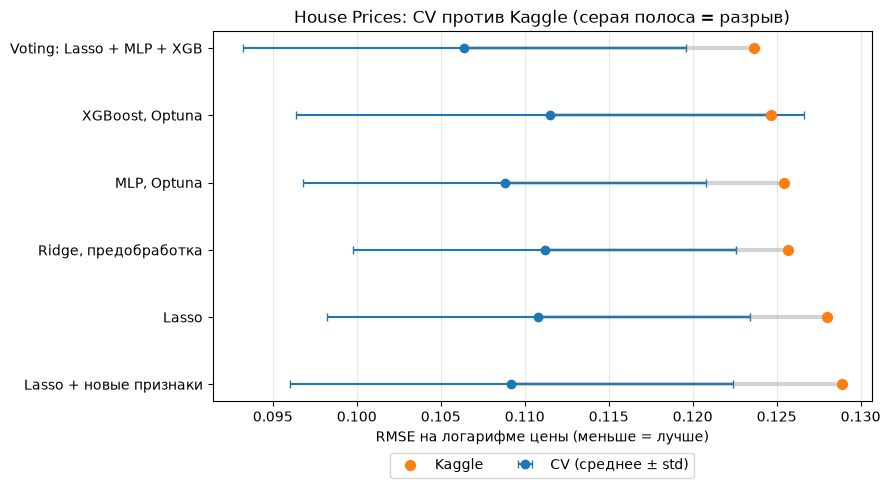

In [10]:
# 10.4 График: CV и Kaggle для каждой модели (без бейзлайна)
plot_df = final[final["name"] != names["linreg"]].sort_values("kaggle", ascending=False)
y_pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(9, 5))
# серая полоса: разрыв между CV и Kaggle
ax.hlines(y_pos, plot_df["cv_mean"], plot_df["kaggle"], color="lightgray", linewidth=3, zorder=1)
ax.errorbar(plot_df["cv_mean"], y_pos, xerr=plot_df["cv_std"], fmt="o", color="tab:blue",
            capsize=3, label="CV (среднее ± std)")
ax.scatter(plot_df["kaggle"], y_pos, color="tab:orange", s=50, zorder=3, label="Kaggle")
ax.set_yticks(y_pos, plot_df["name"])
ax.set_xlabel("RMSE на логарифме цены (меньше = лучше)")
ax.set_title("House Prices: CV против Kaggle (серая полоса = разрыв)")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

In [11]:
# 10.5 Сохраняем таблицу и график в репозиторий
from pathlib import Path

reports = Path(config.reports_dir)
reports.mkdir(exist_ok=True)
final.round(4).to_csv(reports / "summary.csv", index=False)
fig.savefig(reports / "cv_vs_kaggle.png", dpi=150, bbox_inches="tight")

### Итоги

- **Финальная модель:** VotingRegressor (Lasso + MLP + XGBoost, параметры из Optuna, равные веса). CV 0.1064 ± 0.0132, Kaggle 0.12364. Лучшая и по CV, и по Kaggle. Бейзлайн был 0.18030, ошибка снизилась на 0.057.
- **Воспроизводимость:** финальная модель описана в `config.yaml`, `python main.py` даёт тот же CV и сабмит, совпадающий с отправленным до последнего знака.
- **CV против Kaggle:** Kaggle хуже CV на 0.013–0.020 у всех моделей. Причина: выбросы 524 и 1299 удалены из train, а похожие дома в test остались (Id 2550). Меньше всего разрыв у XGBoost (0.0131): деревья не экстраполируют. Больше всего у Lasso с новыми признаками (0.0197).
- **Порядок одиночных моделей на CV и Kaggle разный:** разница между ними 0.001–0.005, меньше std по фолдам (0.012–0.015), это шум. Решения принимались по CV, и ансамбль устойчиво лучший в обоих рейтингах.